# Tree ensembles: averaging, randomization, and functional optimization

## 1. Introduction and learning objectives

Ensembles combine predictors, but the method of combination matters. Bagging averages models fitted to bootstrap samples. A random forest also samples candidate features at each node. Gradient boosting constructs an additive predictor sequentially by fitting directions that reduce a declared loss. Averaging repeated copies of one deterministic fit adds no information; adding poorly controlled model selection adds another source of optimism.

Learn to derive an averaging variance identity and bootstrap inclusion probability, implement bounded regression/classification forests and out-of-bag accounting, derive and verify boosting gradients, and compare methods with matched data and budgets. Connect statistical averaging to later model ensembles and functional descent to later neural-network objectives without claiming the algorithms are interchangeable.

**Prerequisites:** [decision trees](decision-trees.ipynb), Stage 00 covariance and stable logarithms, Stage 01 evaluation and gradient descent, and [information and decisions](probability-information-and-decisions.ipynb). All required models remain manual NumPy implementations. This chapter is self-contained in execution: displayed reference snippets include their small base learner and depend only on earlier snippets **within this chapter**. Default Run All uses none of these implementations.

## 2. Prerequisites and mathematical foundations

For real-valued prediction errors $E_1,\ldots,E_B$ with equal variance $\sigma^2$ and equal pairwise correlation $\rho$,
$$\operatorname{Var}\left(\frac1B\sum_b E_b\right)=\sigma^2\left[\rho+\frac{1-\rho}{B}\right].$$
Derive this by summing all $B$ variances and $B(B-1)$ covariances, then dividing by $B^2$. It describes a chosen distribution over errors with the stated symmetry assumptions. For variance across repeated training sets at a fixed query, those repetitions define the randomness. Correlating two fitted predictors across different query points estimates a different quantity. Pairwise correlations must also define a valid covariance matrix; arbitrary negative values are not valid for every $B$.

A bootstrap bag draws $n$ row indices independently with replacement from the $n$ training rows. One row is absent with probability $q_n=(1-1/n)^n$ for $n>1$, approaching $e^{-1}$. Expected distinct included rows equal $n(1-q_n)$. Bags have $n$ entries but generally fewer than $n$ distinct observations. Out-of-bag (OOB) prediction for training row $i$ uses only trees whose bags omit $i$. With $B$ independently drawn bags, its OOB count is Binomial$(B,q_n)$ and the probability of no eligible tree is $(1-q_n)^B$. OOB predictions for different rows are dependent.

**Hand values:** for $n=4$, $q_n=(3/4)^4=81/256$, expected distinct rows $175/64=2.734375$, and three bags leave a row with no OOB predictor with probability $(175/256)^3\approx.3194$. Missing OOB coverage must be reported; it must not become a made-up zero prediction. With $\sigma^2=4$, $\rho=.25$, and $B=5$, averaged variance is $1.6$, approaching a floor of $1$ under these assumptions.

**Study workflow:** attempt each dedicated answer first, then reveal its hint or worked solution. Reference Python is displayed Markdown and is not executed by Run All. Snippet dependencies refer only to this chapter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 02.05.01 — Distinguish three sources of ensemble diversity

**Type:** Conceptual · **Answer:** Markdown

Compare fitting the same deterministic tree 12 times, fitting 12 trees to bootstrap bags, and fitting bootstrap trees with a fresh subset of candidate features at every node. Explain why a feature subset fixed once per tree is a different procedure. Does diversity alone guarantee improved prediction?

**Expected outcome:** specified sources of randomness, identical-fit behavior, node-level feature sampling, and a strength-versus-dependence limitation.

**Your response to Exercise 02.05.01**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.05.01**

Averaging identical outputs leaves them unchanged. A weaker but less correlated base learner may still be worse overall.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.05.01**

Repeated deterministic fits on unchanged data produce identical predictors, so their mean/vote equals one fit. Bootstrap bags change row multiplicities. Forest feature sampling further changes which splits can compete at each node; it is not a once-per-tree fixed subspace. Randomizing too aggressively can discard useful predictors or stop growth at an unhelpful node. Reduced dependence can help variance, but bias, individual error, task loss and compute also matter. The variance identity requires its stated error-distribution assumptions and is not a universal finite-sample accuracy theorem.

</details>

## 3. Theoretical development and worked examples

### Averaging and honest internal evaluation

For regression, average tree outputs. For classification, **hard voting** averages one-hot tree class decisions; **soft voting** averages leaf probability vectors and then chooses a maximum component. They can disagree: positive-class leaf probabilities $(.51,.51,0)$ give two positive hard votes but soft mean $.34$. Neither average is automatically calibrated. Our interface offers both and names which one produced an evaluation.

Each bootstrap tree can miss a rare class entirely. Encode training classes once at forest level so that every tree output has the same columns, including zero mass for absent classes. With deterministic smallest-label tie rules, global sorted integer labels remain meaningful even when an individual bag contains only one class. OOB accounting must use **absence from the bag**, not the number of times a row appears in it.

The required presets fit raw generated numeric features, so no globally fitted preprocessing leaks into OOB predictions. A supervised feature selector fitted on all training labels would make a supposedly omitted row influence its OOB prediction. To estimate the whole pipeline by OOB, learn such components inside each bag or use a separate valid resampling design. Repeated OOB-based hyperparameter selection makes OOB part of model selection; it is not an untouched final test estimate.

### Gradient boosting as loss reduction in prediction space

Let $F\in\mathbb R^n$ be training scores and $\widehat R(F)=n^{-1}\sum_i\ell(y_i,F_i)$. Define the empirical inner product $\langle a,b\rangle_n=n^{-1}\sum_i a_i b_i$. Its gradient has coordinates $\partial\ell/\partial F_i$; under the ordinary Euclidean inner product the gradient is divided by $n$. State the convention rather than accidentally averaging twice.

For half-squared error, $\ell(y,F)=\tfrac12(y-F)^2$, a negative-gradient target is $r_i=y_i-F_i$. For binary log loss with logits,
$$\ell(y,F)=\log(1+e^F)-yF,\qquad r_i=y_i-\sigma(F_i),\quad\sigma(F)=\frac1{1+e^{-F}}.$$
Use stable log-domain evaluation. Initialize squared-error boosting with $F_0=\bar y$. For binary labels with both classes observed, initialize with the log empirical prior odds. Fit a small **regression** tree $h_m$ to residual targets and update $F_m=F_{m-1}+\eta h_m$. Even classification boosting uses real-valued regression-tree directions, not a majority-vote classifier at each round.

This is a first-order fixed-step teaching algorithm. It does not implement per-leaf Newton updates, a line search, histogram approximation, missing-value routing or second-order production boosters. We bound $0<\eta\le1$, the number of stages, depth and leaf size. A validation-based stage choice must be made without repeatedly inspecting final test observations.

**One-step squared-loss example:** $x=(0,1,2,3)$, $y=(0,0,2,2)$ gives $F_0=1$, residuals $(-1,-1,1,1)$ and a depth-one residual tree with leaves $(-1,1)$. At $\eta=.5$, scores become $(.5,.5,1.5,1.5)$ and average half-MSE falls from $.5$ to $.125$. For binary labels $(0,0,1,1)$ the initial logit is zero and residual leaves are $(-.5,.5)$; at $\eta=1$, average log loss becomes $\log(1+e^{-.5})\approx.4740769842$.

### Additive loss and reweighting: an AdaBoost connection

For signed labels $y_i\in\{-1,1\}$ and signed weak prediction $h_i$, exponential loss adds a stage $F_i+\beta h_i$. With normalized weights $w_i\propto e^{-y_iF_i}$ and weighted error $\epsilon=\sum_iw_i1[y_i\ne h_i]$, the stage-dependent loss is proportional to $(1-\epsilon)e^{-\beta}+\epsilon e^\beta$. For $0<\epsilon<1/2$, its minimizer is $\beta=\tfrac12\log((1-\epsilon)/\epsilon)$. This explains an adaptive reweighting mechanism. Zero error gives an infinite unregularized optimum; error $1/2$ gives no useful stage. A practical extension must declare its stop/cap policy. This chapter verifies the analytical step; its required executable booster uses squared/logistic gradients, not an unstated AdaBoost implementation.

### Exercise 02.05.02 — Derive averaging variance and OOB coverage

**Type:** Mathematical · **Answer:** Markdown

Derive the variance identity by expanding all covariance terms and the bootstrap absence probability by independent row draws. Compute the hand values for $n=4$ and $B=3$, including the probability of zero OOB coverage. Explain which randomness is being averaged in each calculation.

**Expected outcome:** explicit assumptions, the finite-$n$ result before its limit, and a coverage limitation for small ensembles.

**Your response to Exercise 02.05.02**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.05.02**

For one row, each draw avoids it with probability $1-1/n$. For one error average, off-diagonal covariance terms occur $B(B-1)$ times.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.05.02**

Variance is $[B\sigma^2+B(B-1)\rho\sigma^2]/B^2$, giving the stated expression. A bootstrap row is absent after all $n$ independent draws with probability $q_n$. Its inclusion indicator has expectation $1-q_n$, so linearity gives $n(1-q_n)$ distinct expected rows without assuming independence between row-inclusion indicators. For $n=4$, $q_n=81/256$, expected distinct rows $175/64$, and with three independent bags zero OOB count has probability $(175/256)^3\approx.31944$. Bag randomness is conditional on the observed training data. A prediction-variance statement over new training samples requires that additional distribution to be specified.

</details>

### Exercise 02.05.03 — Derive and check a reweighted exponential-loss stage

**Type:** Mathematical · **Answer:** Markdown

Differentiate $(1-\epsilon)e^{-\beta}+\epsilon e^\beta$ and derive the stage weight. At $\epsilon=1/4$, compute $\beta$, the minimized loss factor and the new total normalized weight on misclassified observations. Discuss the zero-error case without silently adding a numerical floor.

**Expected outcome:** $\beta=\tfrac12\log3$, factor $\sqrt3/2$, and post-update error-group mass $.5$, with an explicit boundary policy.

**Your response to Exercise 02.05.03**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.05.03**

The update multiplies wrong observations by $e^\beta$ and correct ones by $e^{-\beta}$ before renormalizing.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.05.03**

Setting the derivative to zero gives $e^{2\beta}=(1-\epsilon)/\epsilon$. Positive second derivative verifies the minimum. At $\epsilon=.25$, both weighted group contributions become $\sqrt3/4$, so the normalizer is $\sqrt3/2$ and the wrong group's new mass is $.5$. If $\epsilon=0$, the unregularized stage optimum diverges rather than being a finite number. A bounded implementation can stop after the perfect weak classifier or explicitly cap its coefficient; a silent floor changes the objective's boundary behavior. The derivation requires signed labels/predictions and is different from the logit residual update above.

</details>

## 4. Guided exercises

### Exercise 02.05.04 — Reconcile voting and one-step boosting

**Type:** Numerical · **Answer:** Markdown

Verify the hard/soft vote disagreement and both one-step boosting examples. For logits $(.5,.5,1.5,1.5)$, would using them as probabilities be valid? State which output space belongs to each loss.

**Expected outcome:** hard positive versus soft negative decision, half-MSE $.125$, binary log loss $.4740769842$, and a score-versus-probability distinction.

**Your response to Exercise 02.05.04**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.05.04**

Regression predictions are unconstrained real values. Logistic scores become probabilities only after the sigmoid.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.05.04**

Two of three probabilities exceed $.5$, so hard voting predicts the positive class, while their soft average $.34$ predicts negative at equal costs. Squared-loss residual fitting updates predictions to $(.5,.5,1.5,1.5)$ and residual magnitudes become $.5$, giving half-MSE $.125$. Logistic fitting instead updates zero logits to $(-.5,-.5,.5,.5)$, so every correct-label probability is $\sigma(.5)$ and mean log loss is $\log(1+e^{-.5})$. Real regression outputs or logits larger than one are valid scores but not probabilities. Averaging probabilities, averaging hard classes and adding logits are different operations.

</details>

### Exercise 02.05.05 — Build a node-randomized base learner

**Type:** Programming · **Answer:** Code

Implement `ensemble_tree` and `ensemble_tree_predict` for MSE regression and Gini classification. Reuse the tree reasoning from the previous chapter, but keep this notebook executable independently. Sample a fresh sorted subset of candidate feature indices at each eligible node. Require an explicit generator when feature sampling is active. Keep depth, leaf-size, positive-gain and midpoint conventions visible.

**Expected outcome:** deterministic full-feature fits, seeded per-node feature sampling, compatible global class columns and independent small-tree checks.

In [ ]:
# Your code for Exercise 02.05.05.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.05.05**

The forest owns the global class encoding. Each leaf can use `bincount` with that fixed class count even if its bag lacks some classes.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.05.05**

Classification targets inside this helper are encoded integers $0,\ldots,K-1$. A node samples its candidate features once, then searches only them. If no sampled feature gives positive gain, it stops; it does not secretly search extra features. Depth is bounded to 0–16. The helper stores no training rows after fitting.

~~~python
def ensemble_data(X, targets, task):
    X = np.asarray(X, dtype=float)
    y = np.asarray(targets)
    if X.ndim != 2 or min(X.shape) == 0 or not np.isfinite(X).all() or y.shape != (len(X),) or not np.isfinite(y).all():
        raise ValueError('finite nonempty features and compatible targets required')
    if task not in ('regression', 'classification'):
        raise ValueError('unknown task')
    if task == 'classification' and not np.issubdtype(y.dtype, np.integer):
        raise ValueError('integer class labels required')
    return X, y.astype(float) if task == 'regression' else y

def ensemble_tree(X, targets, task='regression', max_depth=4, min_leaf=2,
                  max_features=None, rng=None, n_classes=None):
    X, y = ensemble_data(X, targets, task)
    d = X.shape[1]
    features = d if max_features is None else max_features
    for value, lo, hi in ((max_depth,0,16), (min_leaf,1,len(X)), (features,1,d)):
        if isinstance(value, (bool,np.bool_)) or not isinstance(value, (int,np.integer)) or not lo <= value <= hi:
            raise ValueError('invalid integer depth, leaf size or feature count')
    if features < d and not isinstance(rng, np.random.Generator):
        raise ValueError('an explicit generator is required for node sampling')
    if task == 'classification':
        if not isinstance(n_classes, (int,np.integer)) or n_classes < 1 or np.any(y < 0) or np.any(y >= n_classes):
            raise ValueError('encoded class labels and global class count required')

    def summary(local):
        if task == 'regression':
            mean = float(local.mean())
            return mean, float(np.mean((local-mean)**2))
        probability = np.bincount(local, minlength=n_classes)/len(local)
        return probability, float(1-np.sum(probability**2))

    def grow(A, b, depth):
        value, impurity = summary(b)
        node = dict(value=value, n=len(b))
        if depth >= max_depth or len(b) < 2*min_leaf or impurity == 0:
            return node
        chosen = np.arange(d) if features == d else np.sort(rng.choice(d,features,replace=False))
        best = None
        for j in chosen:
            values = np.unique(A[:,j])
            for low, high in zip(values[:-1], values[1:]):
                threshold = low/2 + high/2
                if not low <= threshold < high:
                    threshold = low
                left = A[:,j] <= threshold
                size = int(left.sum())
                if min(size,len(b)-size) < min_leaf:
                    continue
                gain = impurity-(size*summary(b[left])[1]+(len(b)-size)*summary(b[~left])[1])/len(b)
                if best is None or gain > best[0]:
                    best = (gain,int(j),float(threshold),left)
        if best is not None and best[0] > 0:
            _, j, threshold, left = best
            node.update(feature=j,threshold=threshold,left=grow(A[left],b[left],depth+1),
                        right=grow(A[~left],b[~left],depth+1))
        return node

    with np.errstate(over='raise',invalid='raise'):
        root = grow(X,y,0)
    return dict(root=root,task=task,n_features=d,n_classes=n_classes)

def ensemble_tree_predict(tree, X):
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or X.shape[1] != tree['n_features'] or not np.isfinite(X).all():
        raise ValueError('finite query matrix with matching feature width required')
    shape = (len(X),) if tree['task'] == 'regression' else (len(X),tree['n_classes'])
    output = np.empty(shape)
    for i, row in enumerate(X):
        node = tree['root']
        while 'left' in node:
            node = node['left'] if row[node['feature']] <= node['threshold'] else node['right']
        output[i] = node['value']
    return output

demo_base = ensemble_tree(np.arange(4.)[:,None], [0.,0.,2.,2.], max_depth=1, min_leaf=1)
assert np.array_equal(ensemble_tree_predict(demo_base, [[0.],[3.]]), [0.,2.])
~~~

</details>

## 5. Implementation challenges

Reference forests retain $Bn$ bootstrap indices to audit OOB exclusion. Predictions accumulate tree outputs instead of allocating a query-by-tree-by-class tensor. Tree storage scales with the total number of nodes. Boosting stores small trees and the training-loss trace; staged query outputs use an explicitly bounded $(n_{\mathrm{query}},M+1)$ array only when requested. Core dependencies remain NumPy and Matplotlib.

### Exercise 02.05.06 — Fit bootstrap forests with isolated random streams

**Type:** Programming · **Answer:** Code

Implement `fit_forest` with a row-sampling generator separate from the node-feature generator. Return trees, bootstrap indices, original sorted classes, task and training row count. With equal seed and tree count, bagging (all features) and feature-sampled forests must use identical bags. Do not require every bootstrap bag to contain every class.

**Expected outcome:** reproducible row multiplicities, matched bags across feature settings, and valid outputs from missing-class bags.

In [ ]:
# Your code for Exercise 02.05.06.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.05.06**

Spawn two generators from a seed sequence. Consuming additional node draws must not change subsequent row bags.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.05.06**

This depends on `ensemble_data` and `ensemble_tree`. A finite forest is a seeded algorithmic object; generator separation makes an intended comparison reproducible. Tree/node randomness still affects fitted predictions. We bound the teaching forest to 1–64 trees; required experiments use 12.

~~~python
def fit_forest(X, targets, task='regression', n_trees=12, max_depth=4, min_leaf=2,
               max_features=None, seed=220):
    X, y = ensemble_data(X,targets,task)
    if isinstance(n_trees,(bool,np.bool_)) or not isinstance(n_trees,(int,np.integer)) or not 1 <= n_trees <= 64:
        raise ValueError('integer tree count 1..64 required')
    classes = None
    if task == 'classification':
        classes, y = np.unique(y,return_inverse=True)
    row_seed, node_seed = np.random.SeedSequence(seed).spawn(2)
    rows = np.random.default_rng(row_seed); nodes = np.random.default_rng(node_seed)
    trees, bags = [], []
    for _ in range(n_trees):
        bag = rows.integers(0,len(X),size=len(X))
        trees.append(ensemble_tree(X[bag],y[bag],task,max_depth,min_leaf,max_features,nodes,
                                   None if classes is None else len(classes)))
        bags.append(bag)
    return dict(trees=trees,bags=bags,classes=classes,task=task,n_training=len(X),n_features=X.shape[1])

demo_forest = fit_forest(np.arange(8.)[:,None], np.arange(8.), n_trees=3, min_leaf=1)
assert all(len(bag) == 8 for bag in demo_forest['bags'])
~~~

</details>

### Exercise 02.05.07 — Predict forests and audit every OOB contributor

**Type:** Programming · **Answer:** Code

Implement `predict_forest(model, X, voting='soft')` and `oob_predictions(model, X, voting='soft')`. Prediction returns original labels and probabilities for classification, or real predictions and `None` for regression. OOB returns averaged eligible outputs and counts; uncovered rows are NaN. Require the original training rows in original order for OOB. Test every contributing tree index independently.

**Expected outcome:** hard/soft semantics, global class alignment, exact exclusion accounting, and missing-coverage reporting without substituting training predictions.

In [ ]:
# Your code for Exercise 02.05.07.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.05.07**

Use a bag's unique included indices to build its exclusion mask. Divide only rows with positive OOB counts.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.05.07**

These functions depend on `ensemble_tree_predict`. OOB output columns use global classes; convert to labels only on covered rows. Shape checks cannot prove that the caller supplied the original row order, so that identity is an explicit interface requirement. The raw-feature presets have no separately fitted preprocessing.

~~~python
def forest_tree_output(tree, X, voting):
    if voting not in ('soft','hard'):
        raise ValueError('voting must be soft or hard')
    output = ensemble_tree_predict(tree,X)
    if tree['task'] == 'classification' and voting == 'hard':
        output = np.eye(tree['n_classes'])[np.argmax(output,axis=1)]
    return output

def predict_forest(model, X, voting='soft'):
    total = None
    for tree in model['trees']:
        output = forest_tree_output(tree,X,voting)
        total = output.copy() if total is None else total+output
    average = total/len(model['trees'])
    if model['task'] == 'regression':
        return average, None
    return model['classes'][np.argmax(average,axis=1)], average

def oob_predictions(model, X, voting='soft'):
    X = np.asarray(X,dtype=float)
    if X.shape != (model['n_training'],model['n_features']) or not np.isfinite(X).all():
        raise ValueError('original finite training rows in original order required')
    shape = (len(X),) if model['task'] == 'regression' else (len(X),len(model['classes']))
    total = np.zeros(shape); counts = np.zeros(len(X),dtype=int)
    for tree, bag in zip(model['trees'],model['bags']):
        excluded = np.ones(len(X),dtype=bool)
        excluded[np.unique(bag)] = False
        total[excluded] += forest_tree_output(tree,X[excluded],voting)
        counts[excluded] += 1
    average = np.full(shape,np.nan)
    covered = counts > 0
    denominator = counts[covered] if average.ndim == 1 else counts[covered,None]
    average[covered] = total[covered]/denominator
    return average, counts

demo_oob, demo_counts = oob_predictions(demo_forest,np.arange(8.)[:,None])
assert np.isnan(demo_oob[demo_counts == 0]).all()
~~~

</details>

### Exercise 02.05.08 — Implement stable boosting objectives and derivatives

**Type:** Programming · **Answer:** Code

Implement `boost_objective(targets, scores, loss)` returning average loss and the negative-gradient targets under the empirical-inner-product convention. Support `squared` (half-MSE) and `logistic` (binary log loss). Independently finite-difference the mean objective and compare it with **negative residual divided by $n$** under Euclidean coordinates. Test extreme logits without clipping.

**Expected outcome:** correct loss normalization, stable score gradients and an explicit distinction between two inner products.

In [ ]:
# Your code for Exercise 02.05.08.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.05.08**

Use `logaddexp` for binary log losses and a stable sigmoid. Do not apply another observation average when constructing residual targets.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.05.08**

This returns residuals for functional fitting, not Euclidean mean-loss gradients. Its binary implementation uses the correct-label logit sign to avoid subtracting two large nearly equal terms. Both classes are required only for finite initial log-prior odds in the fitter, not for evaluating an already supplied score vector.

~~~python
def boost_objective(targets, scores, loss):
    y = np.asarray(targets,dtype=float); scores = np.asarray(scores,dtype=float)
    if y.ndim != 1 or len(y) == 0 or scores.shape != y.shape or not np.isfinite(y).all() or not np.isfinite(scores).all():
        raise ValueError('compatible nonempty finite target and score vectors required')
    with np.errstate(over='raise',invalid='raise'):
        if loss == 'squared':
            residual = y-scores
            return float(np.mean(residual**2)/2), residual
        if loss != 'logistic' or not np.isin(y,[0.,1.]).all():
            raise ValueError('known loss and binary logistic targets required')
        probability = np.exp(-np.logaddexp(0,-scores))
        value = np.mean(np.logaddexp(0,np.where(y == 1,-scores,scores)))
        return float(value), y-probability

assert np.allclose(boost_objective([0.,2.],[1.,1.],'squared')[1],[-1.,1.])
assert np.isfinite(boost_objective([0.,1.],[1000.,-1000.],'logistic')[0])
~~~

</details>

### Exercise 02.05.09 — Train and inspect first-order gradient boosting

**Type:** Programming · **Answer:** Code

Implement `fit_gradient_boost` using residual regression trees and fixed step `learning_rate`, plus `staged_boost_scores` for bounded inspection. Require 1–64 stages, $0<\eta\le1$, explicit depth/leaf limits and both labels for logistic fitting. Store a loss trace including initialization. Evaluate staged scores using the named objective before making any validation-based stage decision.

**Expected outcome:** exact one-step hand states, reproducible loss traces, correct regression trees for classification loss, and a documented first-order scope.

In [ ]:
# Your code for Exercise 02.05.09.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.05.09**

Initialize with a target mean or empirical log prior odds. A stage fits residuals as a regression task regardless of the outer loss.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.05.09**

This depends on `ensemble_data`, `ensemble_tree`, `ensemble_tree_predict` and `boost_objective`. The staged output intentionally includes initialization as column zero; required query sizes keep that array small. There is no hidden early stopping or Newton rescaling.

~~~python
def fit_gradient_boost(X, targets, loss='squared', n_stages=12, learning_rate=.1, max_depth=2, min_leaf=3):
    X, y = ensemble_data(X,targets,'regression')
    if isinstance(n_stages,(bool,np.bool_)) or not isinstance(n_stages,(int,np.integer)) or not 1 <= n_stages <= 64:
        raise ValueError('integer stage count 1..64 required')
    if not np.isfinite(learning_rate) or not 0 < learning_rate <= 1:
        raise ValueError('learning rate in (0,1] required')
    if loss == 'squared':
        initial = float(y.mean())
    elif loss == 'logistic' and np.isin(y,[0.,1.]).all() and 0 < y.mean() < 1:
        prior = y.mean(); initial = float(np.log(prior)-np.log1p(-prior))
    else:
        raise ValueError('known loss and both classes for logistic fitting required')
    scores = np.full(len(y),initial)
    history = [boost_objective(y,scores,loss)[0]]; trees = []
    for _ in range(n_stages):
        _, residual = boost_objective(y,scores,loss)
        tree = ensemble_tree(X,residual,'regression',max_depth,min_leaf)
        scores += learning_rate*ensemble_tree_predict(tree,X)
        trees.append(tree); history.append(boost_objective(y,scores,loss)[0])
    return dict(trees=trees,initial=initial,learning_rate=float(learning_rate),loss=loss,
                training_loss=np.array(history),n_features=X.shape[1])

def staged_boost_scores(model, X):
    X = np.asarray(X,dtype=float)
    if X.ndim != 2 or X.shape[1] != model['n_features'] or not np.isfinite(X).all():
        raise ValueError('finite compatible query matrix required')
    scores = np.empty((len(X),len(model['trees'])+1)); scores[:,0] = model['initial']
    for m, tree in enumerate(model['trees'],start=1):
        scores[:,m] = scores[:,m-1] + model['learning_rate']*ensemble_tree_predict(tree,X)
    return scores

demo_boost = fit_gradient_boost(np.arange(4.)[:,None],[0.,0.,2.,2.],n_stages=1,
                                learning_rate=.5,max_depth=1,min_leaf=1)
assert np.allclose(staged_boost_scores(demo_boost,np.arange(4.)[:,None])[:,-1],[.5,.5,1.5,1.5])
assert np.allclose(demo_boost['training_loss'],[.5,.125])
~~~

</details>

## 6. Experiments and visualizations

These plots evaluate analytical formulas under declared assumptions. They are not measured forest error curves. The variance floor depends on equal error variances/correlations, and expected OOB coverage does not guarantee that each observed row has a predictor.

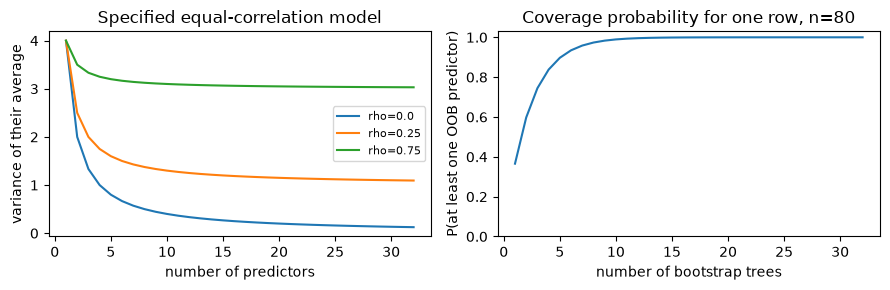

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
demo_trees = np.arange(1, 33)
demo_variance = {}
for rho in (0.,.25,.75):
    demo_variance[rho] = 4*(rho+(1-rho)/demo_trees)
    axes[0].plot(demo_trees,demo_variance[rho],label=f'rho={rho}')
axes[0].set(xlabel='number of predictors',ylabel='variance of their average',title='Specified equal-correlation model')
axes[0].legend(fontsize=8)
demo_absent = (1-1/80)**80
demo_coverage = 1-(1-demo_absent)**demo_trees
axes[1].plot(demo_trees,demo_coverage)
axes[1].set(xlabel='number of bootstrap trees',ylabel='P(at least one OOB predictor)',ylim=(0,1.03),title='Coverage probability for one row, n=80')
fig.tight_layout(); plt.show()

### Exercise 02.05.10 — Compare bagging and node-feature sampling with matched bags

**Type:** Experimental · **Answer:** Code

For seeds 221–223, generate independent training/validation sets of 100/160 rows, with four standard-normal features and target $X_0^2+.5X_1+\epsilon$, $\epsilon\sim\mathcal N(0,.3^2)$. Fit 12 regression trees with depth four and leaf size three, comparing all four candidate features to two per node. Use equal seeds and assert equal bootstrap bags. Report validation MSE, OOB MSE on covered rows, coverage, total node count and elapsed time. Keep test evaluation separate.

**Expected outcome:** actual paired records with matched row bags, named model differences and no unsupported claim that either setting must win.

In [ ]:
# Your code for Exercise 02.05.10.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.05.10**

OOB counts are computed independently of validation. Exclude uncovered rows from the metric and report how many were excluded.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.05.10**

This depends on forest references. Equal bags control one random component; different node candidate sets still change the fitted predictors. A three-seed check is a bounded sensitivity analysis. OOB metrics use fewer trees per row and should not be presented as independent test observations.

~~~python
from time import perf_counter

demo_forest_records = []
for seed in range(221,224):
    rng = np.random.default_rng(seed); data = []
    for size in (100,160):
        X = rng.normal(size=(size,4))
        y = X[:,0]**2 + .5*X[:,1] + rng.normal(0,.3,size)
        data.append((X,y))
    (train_X,train_y),(valid_X,valid_y) = data
    bags = None
    for features in (4,2):
        started = perf_counter()
        model = fit_forest(train_X,train_y,n_trees=12,max_depth=4,min_leaf=3,max_features=features,seed=seed)
        if bags is not None:
            assert all(np.array_equal(a,b) for a,b in zip(bags,model['bags']))
        bags = model['bags']
        predicted,_ = predict_forest(model,valid_X)
        oob,counts = oob_predictions(model,train_X); covered = counts > 0
        def nodes(node):
            return 1 if 'left' not in node else 1+nodes(node['left'])+nodes(node['right'])
        demo_forest_records.append((seed,features,float(np.mean((predicted-valid_y)**2)),
                                    float(np.mean((oob[covered]-train_y[covered])**2)),float(covered.mean()),
                                    sum(nodes(t['root']) for t in model['trees']),perf_counter()-started))
assert len(demo_forest_records) == 6
print('Measured forest validation/OOB records:',demo_forest_records)
~~~

</details>

### Exercise 02.05.11 — Evaluate stage count under a fixed boosting budget

**Type:** Experimental · **Answer:** Code

Use seed 224 to generate 120 training and 160 validation rows with three standard-normal features. For regression use $y=\sin(2X_0)+.3X_1+\mathcal N(0,.2^2)$; independently draw a binary label with probability $\sigma(2X_0-X_1)$. Fit 12 stages at $\eta=.3$, depth two and leaf size three for each loss. Plot actual train/validation loss traces, report a validation-selected stage (including initialization), and record elapsed time and model size. Explain why its selected validation value is not a final test result.

**Expected outcome:** measured loss curves, correct logit/probability handling, bounded model selection and no invented performance conclusion.

In [ ]:
# Your code for Exercise 02.05.11.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.05.11**

Compute every stage's validation objective from its raw scores. One dataset can have different target-generating models for the two separate tasks.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.05.11**

This depends on boosting references. The two tasks share observations but have separately specified responses; they are not comparable by raw objective magnitudes. The shown trace is an actual run, not a promise of monotone validation improvement. Refit/final-test policies belong in the capstone after choices are fixed.

~~~python
demo_rng = np.random.default_rng(224); demo_boost_data = []
for size in (120,160):
    X = demo_rng.normal(size=(size,3))
    regression = np.sin(2*X[:,0])+.3*X[:,1]+demo_rng.normal(0,.2,size)
    probability = np.exp(-np.logaddexp(0,-(2*X[:,0]-X[:,1])))
    binary = demo_rng.binomial(1,probability)
    demo_boost_data.append((X,regression,binary))
fig, axes = plt.subplots(1,2,figsize=(9,3))
demo_boost_records = []
for axis,index,loss in zip(axes,(1,2),('squared','logistic')):
    train_X = demo_boost_data[0][0]; valid_X = demo_boost_data[1][0]
    train_y = demo_boost_data[0][index]; valid_y = demo_boost_data[1][index]
    started = perf_counter()
    model = fit_gradient_boost(train_X,train_y,loss,n_stages=12,learning_rate=.3,max_depth=2,min_leaf=3)
    scores = staged_boost_scores(model,valid_X)
    validation = np.array([boost_objective(valid_y,scores[:,m],loss)[0] for m in range(scores.shape[1])])
    selected = int(np.argmin(validation))
    demo_boost_records.append((loss,selected,float(validation[selected]),perf_counter()-started))
    axis.plot(model['training_loss'],label='training'); axis.plot(validation,label='validation')
    axis.set(xlabel='stage (0 = initialization)',ylabel='declared average loss',title=loss)
    axis.legend(fontsize=8)
fig.tight_layout(); plt.show()
print('Measured boosting selection records:',demo_boost_records)
~~~

</details>

## 7. Interpretation and critical analysis

Ensemble size affects compute and variance of aggregation; tree shape and feature choices affect the predictor family; stage size and residual fitting affect a sequential optimizer. Keep those interventions separate. A larger forest can approach a stable poor predictor. A booster can keep decreasing training loss while validation worsens. An OOB estimate can become optimistic after repeated selection. The specific claims need their own controls and evidence.

### Bounded primary-source study

Read [Breiman (2001), Random Forests, §3.1 and §4](https://www.stat.berkeley.edu/~breiman/randomforest2001.pdf) for OOB contributor definitions and feature sampling at each node. Translate the contributor rule into an explicit index set, verify it on tiny bags, and state the difference between the paper's hard voting and this chapter's optional soft voting. The bounded study does not reproduce the full paper's error bounds or benchmarks.

### Exercise 02.05.12 — Audit an OOB or convergence claim precisely

**Type:** Critical · **Answer:** Markdown

Using the selected source, write an assumption/evidence table for the claim that an internal estimate can replace a held-out evaluation. Include OOB coverage, tuning reuse, preprocessing, grouped/time data and the difference between convergence with more trees and good population prediction. Name what your local experiment can establish.

**Expected outcome:** the exact OOB contributor definition, a bounded numerical check and clearly limited statistical conclusions.

**Your response to Exercise 02.05.12**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.05.12**

Conditional randomization of trees and sampling a new dataset are different sources of uncertainty. The estimate can be used for selection and then no longer be an untouched final audit.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.05.12**

The eligible set for row $i$ is $\{b:i\notin\mathrm{bag}_b\}$, not every tree in which $i$ has low multiplicity. The independent bag-index check establishes that definition on the tested arrays, and measured coverage describes the finite ensemble. It does not prove universal unbiasedness for the selected whole pipeline. Global supervised preprocessing, repeated tuning and dependence between rows can break a simple internal-validation interpretation. Grouped/time data require splits respecting their sampling structure. Convergence of an average under a fixed randomization distribution does not say its limit has low error, nor that finite-size error must improve monotonically. Preserve the capstone's final evaluation protocol and distinguish hard votes from averaged leaf probabilities.

</details>

### Exercise 02.05.13 — Explain why a booster differs from a probability ensemble

**Type:** Critical · **Answer:** Markdown

An engineer proposes averaging the classification booster's per-stage sigmoid outputs instead of adding its residual-tree logits. Explain what model this creates and why it no longer follows the trained additive objective. Discuss when independent model averaging could still be a valid separate experiment.

**Expected outcome:** a precise score-space argument, an alternative evaluated model definition and no unsupported probability-calibration claim.

**Your response to Exercise 02.05.13**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.05.13**

The residual trees were trained against the current additive score; they are not independently fitted probability models.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.05.13**

The booster defines $F_M=F_0+\eta\sum_m h_m$ and predicts $\sigma(F_M)$. A residual tree output can be negative and is a direction in score space, not a standalone calibrated classifier. Averaging $\sigma(h_m)$ or partial-stage probabilities produces another function that was not optimized by the stated update rule. Independent full-model averaging can be studied with declared seeds, weights and a validation protocol; it needs its own probability/decision evaluation and compute comparison. Neither averaging probabilities nor adding logits automatically establishes calibration or uncertainty coverage.

</details>

## 8. Review questions and knowledge checks

### Exercise 02.05.14 — Check gradient normalization at a fixed score snapshot

**Type:** Numerical · **Answer:** Markdown

For binary targets $(0,1)$ and scores $(0,0)$, compute average log loss, residual targets, Euclidean mean-loss gradient and directional derivative along $h=(-1,1)$. Repeat the derivative using a central difference of the independently written mean log-loss objective.

**Expected outcome:** loss $\log2$, residuals $(-.5,.5)$, gradient $(.25,-.25)$, and derivative $-.5$, with a stated finite-difference step.

**Your response to Exercise 02.05.14**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.05.14**

The Euclidean gradient includes $1/n$; its dot product with the direction gives the scalar directional derivative.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.05.14**

Each probability is $.5$. The negative-gradient target under the empirical metric is $y-p=(-.5,.5)$, while the ordinary gradient of the averaged objective is $(p-y)/2=(.25,-.25)$. Dotting with $(-1,1)$ gives $-.5$. A central difference $[R(F+\epsilon h)-R(F-\epsilon h)]/(2\epsilon)$ for a moderate step such as $10^{-5}$ agrees within tolerance. Do not compare residuals directly to a finite-difference gradient of the averaged Euclidean objective without the factor and sign conversion. Finite differences test one local snapshot, not the statistical adequacy of the loss.

</details>

### Exercise 02.05.15 — State an ensemble mastery gate

**Type:** Conceptual · **Answer:** Markdown

Explain bag multiplicity, node-level randomization, missing OOB coverage, hard/soft aggregation, functional-gradient scaling and validation-based stage choice. Point to one independent index audit, one gradient check, one exact one-step state, and measured matched-budget evidence. State a limitation you cannot remove by simply adding trees.

**Expected outcome:** explain/implement/verify/evaluate evidence and a research claim bounded by actual assumptions and measurements.

**Your response to Exercise 02.05.15**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.05.15**

Keep statistical model averaging, sequential optimization and final evaluation roles distinct.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.05.15**

Bootstrap bags encode repeated row indices, and feature subsets are redrawn at each eligible node. OOB aggregation excludes every tree that saw the row and reports uncovered rows; its labels and columns use global classes. Hard votes and soft probability means can disagree. Boosting fits real residual directions from a declared loss, with its averaging convention explicit, then selects a stage using permitted validation data. Index-level OOB reconstruction, independent finite differences and hand recurrences test algorithmic contracts. Matched seed/data/bag measurements support a bounded comparison. More trees cannot repair arbitrary shift, leakage, a systematically biased feature representation or an invalid sampling design.

</details>

## 9. Summary and next learning steps

You connected variance reduction, row and feature randomization, and sequential functional optimization to their concrete implementation contracts. Preserve seeds and independent random streams, global class alignment, contributor counts, objective normalization and score-space semantics. Treat convergence, probability quality and final evaluation as distinct questions requiring their own evidence.

Before advancing, submit derivations, both forest tasks, stable squared/logistic boosting, independent index/gradient/state checks, matched measured experiments and the bounded source audit. Next: margins, constrained optimization and kernels, then statistical learning theory and the shared classical benchmark. Return to the [stage guide](README.md) or [full learning path](../../README.md); remaining planned units are not published material.